![Banner](../../../../Images/Banner/03_spatial_analysis/03_08_banner_spatial_analysis_capstone.png)




# Farmer Information Networks and Technology Diffusion



This is Capstone 6 of the spatial analysis module (Part 7). Extension advice spreads mostly from farmer to farmer, and mostly between neighbours. This case study asks which farmers to train first so that knowledge travels furthest, on a synthetic advice network.

**Data:** farmer locations (`farmers.geojson`) and directed ties (`farmer_ties.csv`) in `Data/00_shared/data_spatial_net/`.

**Library:** `geolattice.spatial_analysis.network_analysis`

## Overview

Farmers learn about seeds, disease advisories, and practices mostly from **other farmers**,
and mostly from farmers nearby. Extension systems therefore face a network question: which
farmers should be trained first so knowledge spreads furthest?

This case study uses the synthetic farmer advice network in `Data/00_shared/data_spatial_net/` with
`geolattice.spatial_analysis.network_analysis` for participation, diffusion centrality, seeding
strategies, and simple / complex contagion.

Topics:

- Directed advice graph and within- vs between-village ties
- Distance decay and dyadic tie formation
- Communities vs villages; leaders and bridges
- Simple vs complex contagion and seeding strategies
- Spatial pattern of adoption



## Setup

The next cell finds the repository root, puts it on the import path, points `DATA` at
`data/data_spatial_net`, and imports `geolattice.spatial_analysis.network_analysis` as `sna`.

**Installation.** This notebook needs installation option 2 (core plus spatial analysis): `pip install "geolattice[analysis]"`. See "Installation options" in the GeoLattice README.

In [1]:
# Display matplotlib figures inline in this Jupyter notebook.
%matplotlib inline

# Standard library imports for path setup and warning control.
import warnings  # silence noisy third-party warnings during demos
from pathlib import Path  # filesystem paths for locating sample data

# Third-party GIS / network / plotting stack used throughout the notebook.
import geopandas as gpd  # GeoDataFrame I/O and geometry ops
import matplotlib.pyplot as plt  # figure and axes creation for maps
import networkx as nx  # graph algorithms and conversions
import numpy as np  # array ops for distances and matrices
import pandas as pd  # tabular display of results
from IPython.display import display  # rich table previews in the notebook

# Hide library warnings so the notebook output stays readable.
warnings.filterwarnings("ignore")  # hide library warnings in notebook output

# ===================================================================
# Setup for spatial network demos.
# Import GeoLattice, point DATA at Data/00_shared/data_spatial_net,
# and import network_analysis as sna.
# ===================================================================

import geolattice

ROOT = Path(geolattice.__file__).resolve().parents[1]
if not (ROOT / "Data").is_dir():
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / "Data").is_dir() and (
            (candidate / "geolattice").is_dir() or (candidate / "src").is_dir()
        ):
            ROOT = candidate
            break
    else:
        raise FileNotFoundError("Could not find the GeoLattice repository root.")

# Synthetic road / town / tract data used by the network chapter.
DATA = ROOT / "Data" / "00_shared" / "data_spatial_net"  # chapter sample-data folder under the repo

# Spatial network helpers from geolattice.
from geolattice.spatial_analysis import network_analysis as sna  # spatial network helpers aliased as sna

# Compact figures with top/right spines removed for a cleaner look.
plt.rcParams.update(  # compact figures with cleaner spines
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}  # notebook step
)
print("repo:", ROOT)  # status line for the notebook reader
print("data:", DATA)  # status line for the notebook reader
print("networkx", nx.__version__, "| geopandas", gpd.__version__)  # status line for the notebook reader

# Logistic regression for tie formation; ARI compares communities to villages.
from sklearn.linear_model import LogisticRegression  # dyadic tie model
from sklearn.metrics import adjusted_rand_score  # community vs village agreement (via sna helper)

# Reproducible RNG for sampling and contagion Monte Carlo.
rng = np.random.default_rng(2026)  # reproducible random generator
# Farmer points (attributes + geometry) and directed advice ties.
farmers = gpd.read_file(DATA / "farmers.geojson").set_index("farmer_id")  # farmer locations and attributes
ties = pd.read_csv(DATA / "farmer_ties.csv")  # directed advice ties between farmers
print(len(farmers), "farmers in", farmers.village.nunique(), "villages |", len(ties), "advice ties")  # status line for the notebook reader
farmers.head()  # run this analysis or plotting step



repo: /home/zia207/Github/GeoLattice
data: /home/zia207/Github/GeoLattice/Data/00_shared/data_spatial_net
networkx 3.6.1 | geopandas 1.1.4


420 farmers in 14 villages | 1492 advice ties


,village,farm_ha,education_yrs,extension_contact,geometry
farmer_id,,,,,
F000,V00,0.44,5,False,POINT (389661.848 4699811.54)
F001,V00,1.61,4,False,POINT (389951.557 4700917.245)
F002,V00,3.57,0,False,POINT (387936.154 4700286.46)
F003,V00,1.94,5,False,POINT (389578.664 4700197.066)
F004,V00,1.71,9,False,POINT (387914.908 4701233.736)


## Part A: The advice network

Direction matters. An edge *i → j* means *i seeks advice from j*, so **information flows j → i**. A farmer's **in-degree** (times named) measures how often others turn to them: a standard proxy for opinion leadership.



In [2]:
# ===================================================================
# Build the directed advice graph and summarise structure / geography.
# ===================================================================

# Directed graph: source asks target for advice.
A = nx.from_pandas_edgelist(ties, "source", "target", create_using=nx.DiGraph)  # NetworkX graph built from the edge table
A.add_nodes_from(farmers.index)  # include isolates with no ties
nx.set_node_attributes(A, farmers.drop(columns="geometry").to_dict("index"))  # run this analysis or plotting step
pos = {f: (p.x, p.y) for f, p in farmers.geometry.items()}  # map layout

# In-degree = how often named as an adviser; out-degree = how many named.
farmers["named_by"] = pd.Series(dict(A.in_degree()))  # run this analysis or plotting step
farmers["names"] = pd.Series(dict(A.out_degree()))  # run this analysis or plotting step

xy = np.c_[farmers.geometry.x, farmers.geometry.y]  # coordinate matrix
idx = {f: k for k, f in enumerate(farmers.index)}  # farmer_id -> row index
# Euclidean tie length (km) and same-village flag for every observed tie.
ties["km"] = [np.hypot(*(xy[idx[s]] - xy[idx[t]])) / 1000 for s, t in zip(ties.source, ties.target)]  # run this analysis or plotting step
ties["same_village"] = [farmers.village[s] == farmers.village[t] for s, t in zip(ties.source, ties.target)]  # run this analysis or plotting step

summary = pd.Series({  # one-line network structure summary
    "farmers": A.number_of_nodes(),  # continue multi-line call
    "ties": A.number_of_edges(),  # continue multi-line call
    "reciprocity": nx.reciprocity(A),  # continue multi-line call
    "share of ties within village": ties.same_village.mean(),  # continue multi-line call
    "median tie length (km)": ties.km.median(),  # continue multi-line call
    "90th pct tie length (km)": ties.km.quantile(0.9),  # continue multi-line call
    "max in-degree (named by)": farmers.named_by.max(),  # continue multi-line call
    "farmers never named": (farmers.named_by == 0).mean(),  # continue multi-line call
    "weakly connected components": nx.number_weakly_connected_components(A),  # continue multi-line call
})
summary.round(3).to_frame("value")  # run this analysis or plotting step



,value
farmers,420.000
ties,1492.000
reciprocity,0.111
share of ties within village,0.920
median tie length (km),0.899
90th pct tie length (km),1.796
max in-degree (named by),13.000
farmers never named,0.040
weakly connected components,3.000


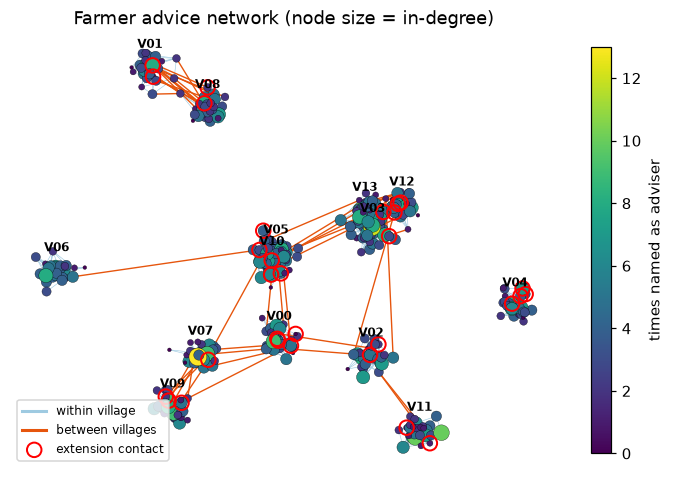

In [3]:
# ===================================================================
# Map the advice network: within-village ties, between-village bridges,
# node size/colour by in-degree, rings for extension contacts.
# ===================================================================

fig, ax = plt.subplots(figsize=(8, 8))  # create figure and primary axes
between = ties[~ties.same_village]  # bridges across villages
within = ties[ties.same_village]  # local village ties
for df, col, lw, lab in [  # notebook step
    (within, "#9ecae1", 0.4, "within village"),  # continue multi-line call
    (between, "#e6550d", 0.9, "between villages"),  # continue multi-line call
]:
    for s, t in zip(df.source, df.target):  # iterate paired sequences together
        ax.plot(*zip(pos[s], pos[t]), color=col, lw=lw, zorder=1)  # draw lines or edges on the axes
    ax.plot([], [], color=col, lw=2, label=lab)  # legend proxy
sc = ax.scatter(  # define sc
    xy[:, 0], xy[:, 1],  # notebook step
    s=6 + 10 * farmers.named_by,  # size ~ in-degree
    c=farmers.named_by, cmap="viridis", zorder=2, edgecolor="k", lw=0.2,  # colour values or constant colour
)
ext = farmers[farmers.extension_contact]  # farmers who talk to extension agents
ax.scatter(  # plot point markers
    ext.geometry.x, ext.geometry.y,  # notebook step
    s=90, facecolor="none", edgecolor="red", lw=1.3, zorder=3, label="extension contact",  # marker size
)
for v, g in farmers.groupby("village"):  # iterate over the collection
    ax.annotate(v, (g.geometry.x.mean(), g.geometry.y.mean() + 1300), fontsize=8, ha="center", weight="bold")  # label a feature near its coordinates
plt.colorbar(sc, ax=ax, shrink=0.6, label="times named as adviser")  # attach a colour bar
ax.legend(loc="lower left", fontsize=8)  # add a legend for mapped layers
ax.set_aspect("equal")  # keep geographic proportions undistorted
ax.set_axis_off()  # hide coordinate ticks for a clean map
ax.set_title("Farmer advice network (node size = in-degree)")  # panel / map title
plt.show()  # render the figure in the notebook



The picture is typical of rural information networks: dense local clusters (villages), a thin web of between-village ties, and a handful of heavily consulted farmers in each village. Notice that farmers with extension contact (red rings) are **not necessarily** the ones others consult.



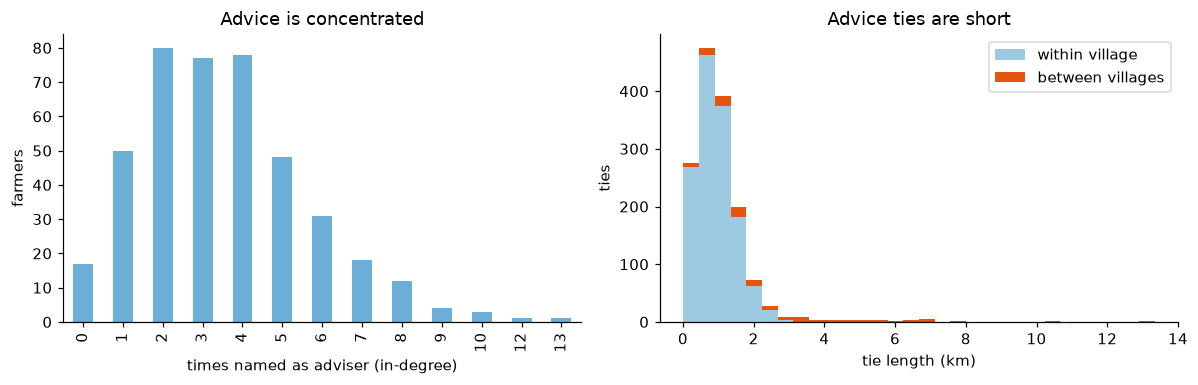

In [4]:
# ===================================================================
# In-degree distribution and stacked histogram of tie lengths.
# ===================================================================

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))  # create a grid of subplot axes
farmers.named_by.value_counts().sort_index().plot.bar(ax=axes[0], color="#6baed6")  # run this analysis or plotting step
axes[0].set(xlabel="times named as adviser (in-degree)", ylabel="farmers", title="Advice is concentrated")  # configure this subplot's labels or title
axes[1].hist(  # continue multi-line call
    [within.km, between.km], bins=30, stacked=True,  # notebook step
    color=["#9ecae1", "#e6550d"], label=["within village", "between villages"],  # artist colour
)
axes[1].set(xlabel="tie length (km)", ylabel="ties", title="Advice ties are short")  # configure this subplot's labels or title
axes[1].legend()  # add a legend
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



## Part B: What makes two farmers connect?

### B1. Distance-decay curve

As in 03.06.1, compute the probability that a pair of farmers is tied as a function of distance, separately for pairs in the same village and in different villages.



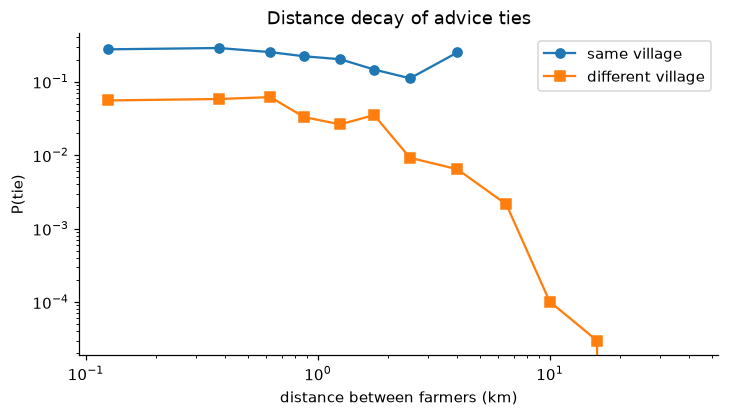

In [5]:
# ===================================================================
# Empirical P(tie) vs distance, split by same vs different village.
# ===================================================================

n = len(farmers)  # number of nodes / farmers
D = np.hypot(xy[:, None, 0] - xy[None, :, 0], xy[:, None, 1] - xy[None, :, 1]) / 1000  # km matrix
vil = farmers.village.to_numpy(dtype=object)  # village labels as an object array
SV = vil[:, None] == vil[None, :]  # same-village boolean matrix
Adj = nx.to_numpy_array(A, nodelist=list(farmers.index))  # directed adjacency
U = np.maximum(Adj, Adj.T)  # undirected presence of a tie in either direction
iu = np.triu_indices(n, 1)  # unique unordered pairs
pairs = pd.DataFrame({"km": D[iu], "same_village": SV[iu], "tie": U[iu]})  # unique unordered farmer pairs
bins = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 5, 8, 12, 20, 60]  # distance bands for empirical P(link)
pairs["band"] = pd.cut(pairs.km, bins)  # run this analysis or plotting step
curve = pairs.groupby(["band", "same_village"], observed=True).tie.mean().unstack()  # P(tie) by distance band and village match

fig, ax = plt.subplots(figsize=(7.5, 3.8))  # create figure and primary axes
mids = [b.mid for b in curve.index]  # bin midpoints for plotting
ax.plot(mids, curve[True], marker="o", label="same village")  # draw lines or edges on the axes
ax.plot(mids, curve[False], marker="s", label="different village")  # draw lines or edges on the axes
ax.set(  # set labels, title, or axis limits
    xscale="log", yscale="log",  # xscale argument
    xlabel="distance between farmers (km)", ylabel="P(tie)",  # x-axis label
    title="Distance decay of advice ties",  # plot or map title
)
ax.legend()  # add a legend for mapped layers
plt.show()  # render the figure in the notebook



Two effects are visible at once: tie probability falls steeply with distance, and **at the same distance**, farmers in the same village are much more likely to be tied. Village membership is a social boundary over and above geography.

### B2. A dyadic tie-formation model

A logistic regression on dyads separates these effects and adds characteristics of the potential adviser. With 175,000 directed pairs and few ties, we use **case-control sampling**: all ties plus a random sample of non-ties. Coefficients on the predictors are unaffected by this sampling; only the intercept shifts.



In [6]:
# ===================================================================
# Dyadic logit for directed ties: distance, village, adviser attributes.
# Down-sample non-ties for a tractable case-control design.
# ===================================================================

src, tgt = np.where(~np.eye(n, dtype=bool))  # all ordered pairs i != j
dy = pd.DataFrame({"i": src, "j": tgt, "tie": Adj[src, tgt]})  # dyadic case-control sample for the logit
# Keep all observed ties and a random sample of non-ties.
dy = pd.concat([dy[dy.tie == 1], dy[dy.tie == 0].sample(20 * int(dy.tie.sum()), random_state=1)])  # dyadic case-control sample for the logit
dy["log_km"] = np.log(D[dy.i, dy.j] + 0.05)  # distance with a small offset
dy["same_village"] = SV[dy.i, dy.j].astype(int)  # run this analysis or plotting step
dy["adviser_log_farm"] = np.log(farmers.farm_ha.values[dy.j])  # target (adviser) farm size
dy["adviser_educ"] = farmers.education_yrs.values[dy.j]  # notebook step
dy["adviser_extension"] = farmers.extension_contact.values[dy.j].astype(int)  # run this analysis or plotting step
Xcols = ["log_km", "same_village", "adviser_log_farm", "adviser_educ", "adviser_extension"]  # logit predictor column names
Xs = (dy[Xcols] - dy[Xcols].mean()) / dy[Xcols].std()  # standardised design matrix
logit = LogisticRegression(C=1e6, max_iter=1000).fit(dy[Xcols], dy.tie)  # raw-scale coefs
logit_s = LogisticRegression(C=1e6, max_iter=1000).fit(Xs, dy.tie)  # comparable magnitudes
pd.DataFrame({  # run this analysis or plotting step
    "coef": logit.coef_[0],  # continue string literal
    "odds ratio": np.exp(logit.coef_[0]),  # continue multi-line call
    "standardised coef": logit_s.coef_[0],  # continue string literal
}, index=Xcols).round(3)  # run this analysis or plotting step



,coef,odds ratio,standardised coef
log_km,-0.976,0.377,-0.969
same_village,2.981,19.717,0.892
adviser_log_farm,0.488,1.628,0.286
adviser_educ,0.063,1.065,0.187
adviser_extension,0.117,1.124,0.025


Reading the table: each doubling of distance multiplies the odds of a tie by about $2^{\beta_{\log km}}$; sharing a village multiplies it several-fold; larger and more educated farmers are sought out more often. Extension contact has little effect, consistent with how the data were generated: having access to extension does not by itself make a farmer someone others consult. This is precisely the situation in which "train the farmers you already reach" may be a weak seeding rule.

> **Caution.** Dyadic models treat pairs as independent, which they are not (reciprocity, transitivity). For inference use ERGMs or dyadic-cluster-robust standard errors; here the model is descriptive.

## Part C: Communities, leaders, and bridges

### C1. Do network communities match villages?



In [7]:
# ===================================================================
# Louvain communities on the undirected advice graph vs village labels.
# ===================================================================

Gu = A.to_undirected()  # ignore direction for community detection
comms = nx.community.louvain_communities(Gu, seed=5)  # Louvain communities / regions
comm_of = {f: k for k, c in enumerate(comms) for f in c}  # define comm_of
farmers["community"] = farmers.index.map(comm_of)  # run this analysis or plotting step
ari = sna.community_label_agreement(farmers.village, farmers.community)  # ARI vs villages
print(  # status line for the notebook reader
    f"{len(comms)} Louvain communities vs {farmers.village.nunique()} villages; "  # run this analysis or plotting step
    f"modularity {nx.community.modularity(Gu, comms):.3f}; adjusted Rand index {ari:.3f}"  # run this analysis or plotting step
)
pd.crosstab(farmers.village, farmers.community).iloc[:6, :8]  # run this analysis or plotting step



11 Louvain communities vs 14 villages; modularity 0.865; adjusted Rand index 0.790


community,0,1,2,3,4,5,6,7
village,,,,,,,,
V00,0,30,0,0,0,0,0,0
V01,0,0,30,0,0,0,0,0
V02,0,0,0,30,0,0,0,0
V03,0,0,0,0,30,0,0,0
V04,0,0,0,0,0,30,0,0
V05,30,0,0,0,0,0,0,0


High agreement: villages are the network's main communities, with occasional merging of neighbouring villages that exchange many ties. The between-village ties are therefore the scarce channel through which knowledge leaves a village.

### C2. Opinion leaders and bridging farmers

Three roles matter for diffusion:

- **Opinion leaders**: high in-degree within their village.
- **Bridges**: high betweenness, or many ties to *other* villages. The **participation coefficient** $P_i = 1 - \sum_c (k_{ic}/k_i)^2$ measures how evenly a farmer's ties spread across communities (0 = all in one village).
- **Diffusion centrality** (Banerjee et al., 2013): expected number of farmers reached if information passes along each tie with probability *q* for *T* rounds, $\sum_{t=1}^{T} (qA)^t \mathbf{1}$.



In [8]:
# ===================================================================
# Role measures: betweenness, participation, diffusion centrality.
# Diffusion centrality uses information flow adviser -> asker (Adj.T).
# ===================================================================

bc = nx.betweenness_centrality(Gu, k=200, seed=1)  # sampled betweenness
# Diffusion centrality on the "information flows j -> i" matrix (transpose of asks-matrix).
Ainfo = Adj.T  # information-flow matrix (adviser -> asker)
q, T_ = 0.25, 4  # transmission probability and horizon used by DC
DC = sna.diffusion_centrality(Ainfo, q=q, T=T_)  # diffusion centrality scores

farmers["betweenness"] = farmers.index.map(bc)  # run this analysis or plotting step
farmers["participation"] = farmers.index.map(  # continue multi-line call
    sna.participation_coefficient(Gu, farmers.village.to_dict())  # cross-village bridging
)
farmers["diffusion_centrality"] = DC  # notebook step
roles = farmers[[  # define roles
    "village", "farm_ha", "education_yrs", "extension_contact", "named_by",  # continue string literal
    "betweenness", "participation", "diffusion_centrality",  # continue string literal
]]
roles.sort_values("diffusion_centrality", ascending=False).head(8).round(3)  # run this analysis or plotting step



,village,farm_ha,education_yrs,extension_contact,named_by,betweenness,participation,diffusion_centrality
farmer_id,,,,,,,,
F237,V07,8.10,6,False,13,0.023,0.000,13.324
F117,V03,3.38,7,False,12,0.005,0.320,12.070
F230,V07,2.18,10,False,9,0.008,0.142,7.785
F392,V13,3.83,7,False,10,0.017,0.314,7.734
F337,V11,1.88,13,False,10,0.003,0.000,7.734
F113,V03,1.74,10,False,7,0.010,0.198,7.238
F028,V00,7.29,4,False,9,0.016,0.000,7.199
F209,V06,1.51,8,False,8,0.022,0.000,7.168


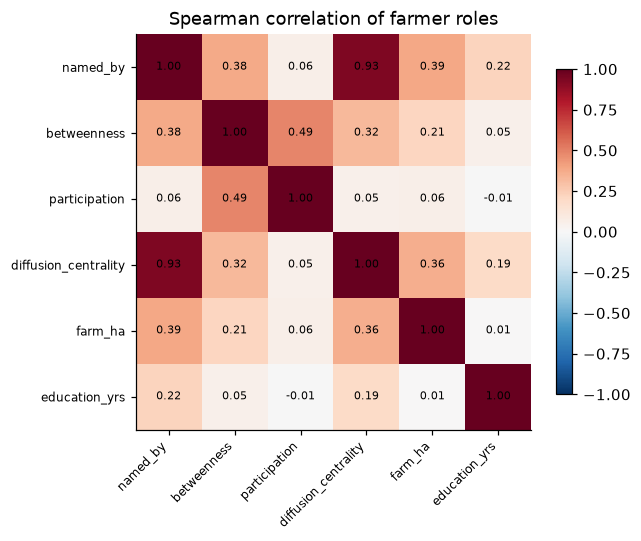

In [9]:
# ===================================================================
# Spearman correlation heatmap among role and attribute measures.
# ===================================================================

cols = ["named_by", "betweenness", "participation", "diffusion_centrality", "farm_ha", "education_yrs"]  # role / attribute columns for the heatmap
fig, ax = plt.subplots(figsize=(5.8, 4.8))  # create figure and primary axes
cm = farmers[cols].corr(method="spearman")  # Spearman correlation among role measures
im = ax.imshow(cm, cmap="RdBu_r", vmin=-1, vmax=1)  # define im
ax.set_xticks(range(len(cols)), cols, rotation=45, ha="right", fontsize=8)  # configure or hide x tick labels
ax.set_yticks(range(len(cols)), cols, fontsize=8)  # configure or hide y tick labels
for a_ in range(len(cols)):  # loop over an integer range
    for b_ in range(len(cols)):  # loop over an integer range
        ax.text(b_, a_, f"{cm.iloc[a_, b_]:.2f}", ha="center", va="center", fontsize=7)  # caption or note in axes / figure coordinates
plt.colorbar(im, ax=ax, shrink=0.8)  # attach a colour bar
ax.set_title("Spearman correlation of farmer roles")  # panel / map title
plt.show()  # render the figure in the notebook



In-degree and diffusion centrality overlap strongly (both reward being consulted by people who are themselves consulted). Betweenness and participation capture a different role, the **bridge**, which is only weakly related to being a local leader.

## Part D: Simulating technology diffusion

### The diffusion models

Each period, a non-adopter considers the adopters among the people they ask for advice ($k_i^{adopt}$ of their $k_i$ advisers):

- **Simple contagion** (information): adopt with probability $1 - (1-q)^{k_i^{adopt}}$, plus a small spontaneous rate. One informed adviser can be enough. Appropriate for awareness of a disease advisory or a market price.
- **Complex contagion** (persuasion): adopt with probability *p* only once the share of adopting advisers reaches a threshold $\theta_i$. Appropriate for costly or risky practices, such as a new variety, zero tillage, or machinery, where farmers want to see several peers succeed first (Beaman et al., 2021).

### Seeding strategies (budget = 14 seed farmers, one per village on average)

| Strategy | Rule |
|---|---|
| Random | 14 farmers at random |
| Extension contacts | farmers who already have extension contact (status quo) |
| Top in-degree | the 14 most-consulted farmers overall |
| Leader per village | the most-consulted farmer in each village (spatially dispersed) |
| Bridges | highest participation coefficient (ties to other villages) |
| Pairs per village | the two most-consulted farmers in 7 villages: concentrates seeds for complex contagion |



In [10]:
# ===================================================================
# Compare seeding strategies for K=14 initial adopters.
# ===================================================================

K = 14  # seed budget
vill_list = sorted(farmers.village.unique())  # define vill_list
order_in = farmers.sort_values(["named_by", "diffusion_centrality"], ascending=False)  # used inside select_seeds
ext_ids = farmers.index[farmers.extension_contact].tolist()  # farmers with extension contact

strategies = [  # seeding strategies to compare
    "Random", "Extension contacts", "Top in-degree",  # continue string literal
    "Leader per village", "Bridges", "Pairs per village",  # continue string literal
]
print(f"{len(ext_ids)} farmers have extension contact")  # status line for the notebook reader
for s in strategies:  # iterate over the collection
    sd = sna.select_seeds(farmers, s, K, rng=np.random.default_rng(0))  # sd argument
    print(  # status line for the notebook reader
        f"{s:20s} seeds in {farmers.loc[sd, 'village'].nunique():2d} villages, "  # run this analysis or plotting step
        f"mean in-degree {farmers.loc[sd, 'named_by'].mean():.1f}"  # run this analysis or plotting step
    )



30 farmers have extension contact
Random               seeds in 11 villages, mean in-degree 3.4
Extension contacts   seeds in 11 villages, mean in-degree 4.4
Top in-degree        seeds in  8 villages, mean in-degree 9.4
Leader per village   seeds in 14 villages, mean in-degree 9.0
Bridges              seeds in  6 villages, mean in-degree 4.4
Pairs per village    seeds in  7 villages, mean in-degree 8.6


In [11]:
# ===================================================================
# Monte Carlo simple vs complex contagion under each seeding strategy.
# ===================================================================

advisers = Adj  # row i: whom i asks (influence comes from named advisers)
theta_i = np.random.default_rng(3).uniform(0.3, 0.6, n)  # heterogeneous persuasion thresholds
results = {}  # collect index / scenario result rows
for model, kw in [("simple", {}), ("complex", {"theta": theta_i})]:  # iterate over the collection
    for s in strategies:  # iterate over the collection
        results[(model, s)] = sna.monte_carlo_contagion(  # call a geolattice.network_analysis helper
            advisers, farmers, s, model=model, reps=200, k=K, seed=11, periods=20, **kw  # notebook step
        )



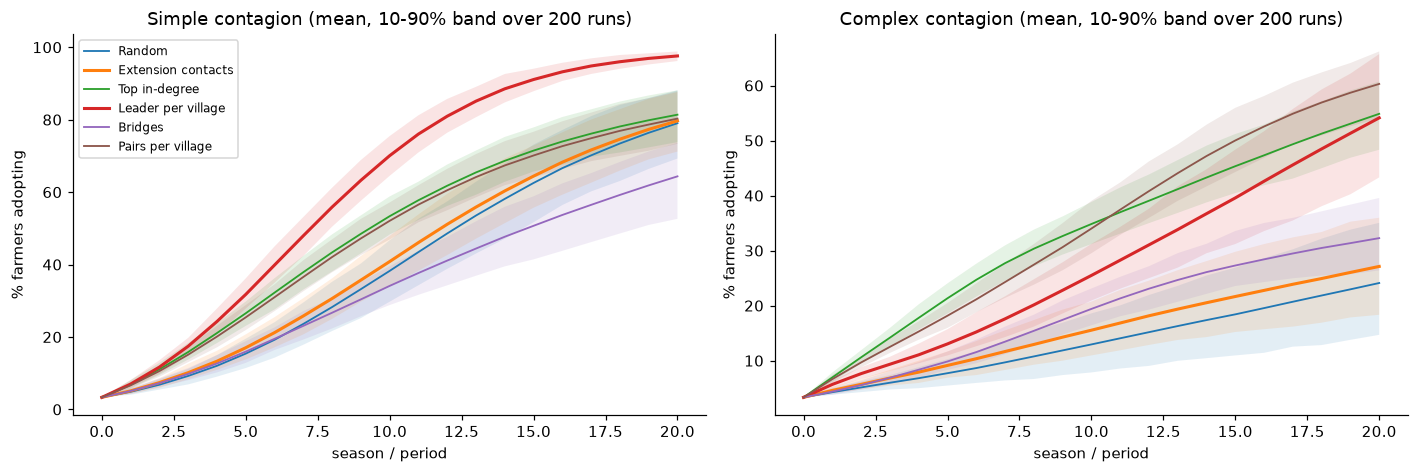

In [12]:
# ===================================================================
# Mean adoption trajectories with 10-90% bands over 200 Monte Carlo runs.
# ===================================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=False)  # create a grid of subplot axes
for ax, model in zip(axes, ["simple", "complex"]):  # iterate paired sequences together
    for s in strategies:  # iterate over the collection
        H = results[(model, s)][0] * 100  # percent adopting by period
        m, lo, hi = H.mean(0), np.percentile(H, 10, 0), np.percentile(H, 90, 0)  # run this analysis or plotting step
        ax.plot(m, label=s, lw=2 if s in ("Leader per village", "Extension contacts") else 1.2)  # draw lines or edges on the axes
        ax.fill_between(range(len(m)), lo, hi, alpha=0.12)  # run this analysis or plotting step
    ax.set(  # set labels, title, or axis limits
        xlabel="season / period",  # x-axis label
        ylabel="% farmers adopting",  # y-axis label
        title=f"{model.capitalize()} contagion (mean, 10-90% band over 200 runs)",  # plot or map title
    )
axes[0].legend(fontsize=8)  # add a legend
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook



In [13]:
# ===================================================================
# Summary table: mean % adopting at periods 5 and 20 by model/strategy.
# ===================================================================

tab = pd.DataFrame({  # build table tab
    (model, f"{when}"): {s: results[(model, s)][0][:, t].mean() * 100 for s in strategies}  # run this analysis or plotting step
    for model in ["simple", "complex"]  # notebook step
    for when, t in [("period 5", 5), ("period 20", 20)]  # run this analysis or plotting step
}).round(1)  # run this analysis or plotting step
tab.columns = pd.MultiIndex.from_tuples(tab.columns)  # assign tab.columns
tab.sort_values(("complex", "period 20"), ascending=False)  # run this analysis or plotting step



simple            complex          
                   period 5 period 20 period 5 period 20
Pairs per village      25.4      80.3     18.2      60.3
Top in-degree          26.5      81.4     21.3      54.9
Leader per village     31.8      97.6     13.0      54.1
Bridges                16.0      64.4      9.9      32.3
Extension contacts     17.0      79.7      9.1      27.1
Random                 15.4      79.0      7.7      24.1

**What the simulations suggest** (for this network and these parameters):

- Under **simple contagion**, **coverage of villages** matters most. Putting one well-connected seed in every village reaches nearly everyone; strategies that leave villages without a seed plateau lower because information must cross the scarce between-village ties. Centrality within the village mainly buys speed.
- Under **complex contagion**, the strategy decides whether the practice takes off at all. Isolated seeds stall because their neighbours never see enough adopting peers; seeds that are well connected within their village, and seeds clustered so that neighbours hear from several of them, do far better.
- Seeding the existing **extension contacts** performs close to random in this network, because extension access is not what makes someone a sought-after adviser (Part B).

These are the same qualitative conclusions reached by field experiments, but magnitudes here depend entirely on assumed parameters (*q*, *p*, θ). Simulation is for comparing designs and understanding mechanisms, not for forecasting adoption rates.

## Part E: Diffusion in space

Take a single complex-contagion run of the best strategy and map **when** each farmer adopts.



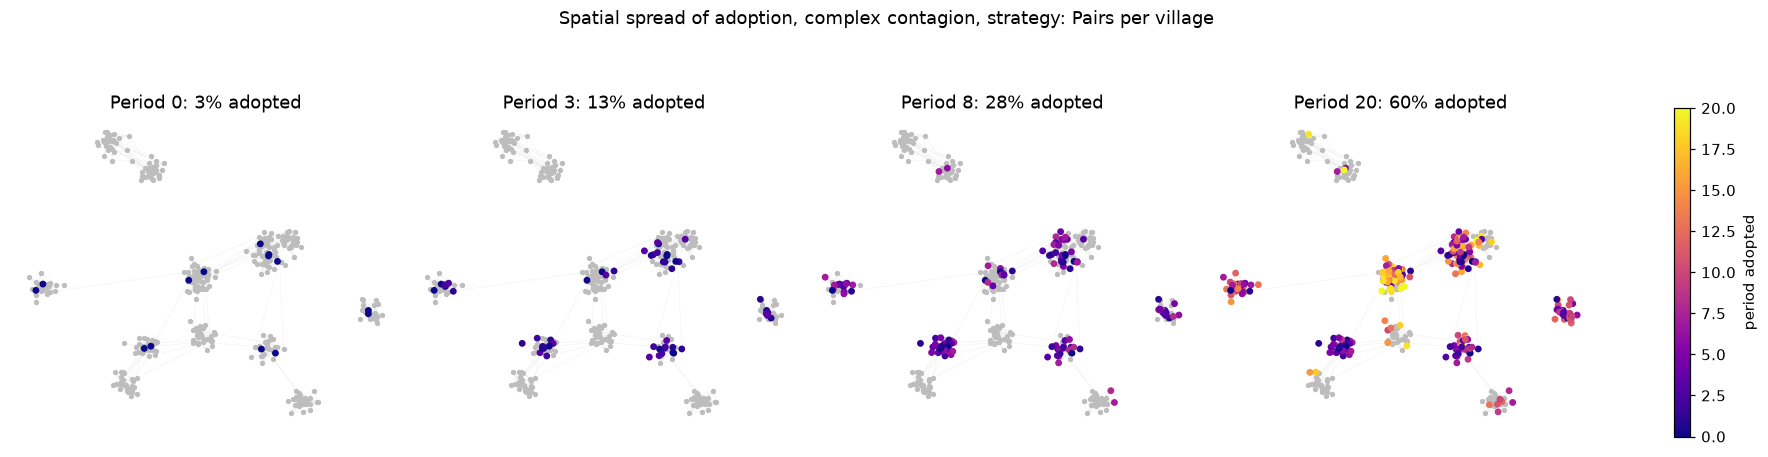

In [14]:
# ===================================================================
# Spatial snapshots of complex contagion under the best seeding strategy.
# ===================================================================

best = tab[("complex", "period 20")].idxmax()  # strategy with highest late adoption
seeds = sna.select_seeds(farmers, best, K, rng=np.random.default_rng(4))  # selected seed farmer ids
h, ta = sna.simulate_contagion(  # call a geolattice.network_analysis helper
    advisers, seeds, list(farmers.index),  # continue multi-line call
    model="complex", theta=theta_i, periods=20, rng=np.random.default_rng(4),  # simple vs complex contagion
)
farmers["adopt_period"] = ta  # first period adopted (NaN if never)

fig, axes = plt.subplots(1, 4, figsize=(16, 4.6), constrained_layout=True)  # create a grid of subplot axes
for ax, t in zip(axes, [0, 3, 8, 20]):  # iterate paired sequences together
    done = farmers.adopt_period <= t  # adopted by this period
    for s, tg in zip(ties.source, ties.target):  # iterate paired sequences together
        ax.plot(*zip(pos[s], pos[tg]), color="#eeeeee", lw=0.3, zorder=0)  # faint ties
    ax.scatter(xy[~done, 0], xy[~done, 1], s=6, color="#bdbdbd")  # not yet adopted
    sc = ax.scatter(  # sc argument
        xy[done, 0], xy[done, 1], s=12,  # notebook step
        c=farmers.adopt_period[done], cmap="plasma", vmin=0, vmax=20,  # colour values or constant colour
    )
    ax.set_title(f"Period {t}: {done.mean()*100:.0f}% adopted")  # panel / map title
    ax.set_aspect("equal")  # keep geographic proportions undistorted
    ax.set_axis_off()  # hide coordinate ticks for a clean map
fig.suptitle(f"Spatial spread of adoption, complex contagion, strategy: {best}")  # shared figure title above all panels
plt.colorbar(sc, ax=axes, shrink=0.7, label="period adopted")  # attach a colour bar
plt.show()  # render the figure in the notebook



Adoption spreads outward from seeds within villages first, then jumps between villages along the rare bridging ties. A plot of **adoption time vs. distance to the nearest seed** and vs. **network distance to the nearest seed** shows which kind of distance governs the process.



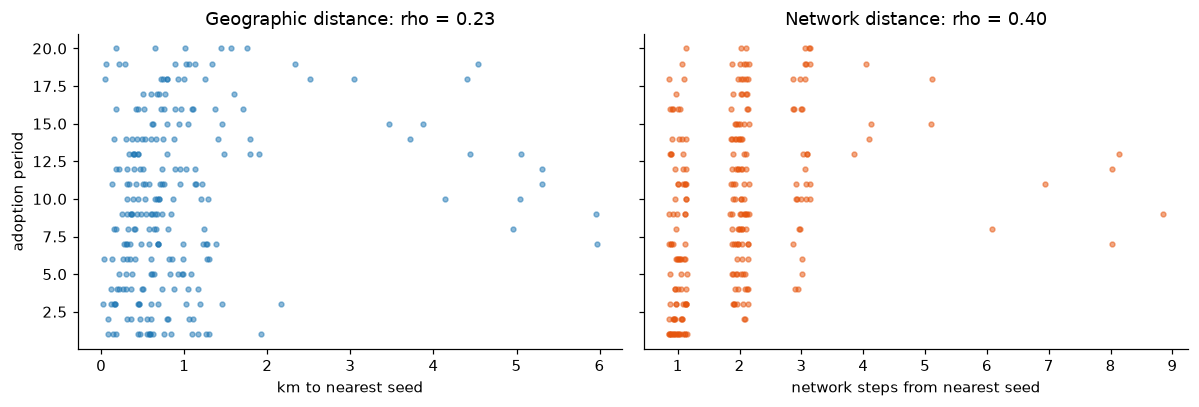

Never adopted by period 20: 40% of farmers; unreachable from seeds through advice ties: 14%


In [15]:
# ===================================================================
# Adoption timing vs geographic km and network steps from nearest seed.
# ===================================================================

seed_idx = np.where(ta == 0)[0]  # indices of initial seeds
geo_to_seed = D[:, seed_idx].min(axis=1)  # km to nearest seed
Ginfo = nx.DiGraph()  # define Ginfo
Ginfo.add_nodes_from(range(n))  # add graph elements
Ginfo.add_edges_from(zip(*np.where(Ainfo > 0)))  # information flows adviser -> asker
net_len = nx.multi_source_dijkstra_path_length(Ginfo, set(seed_idx))  # run Dijkstra from this source
net_to_seed = np.array([net_len.get(k, np.nan) for k in range(n)])  # hops from nearest seed
ok = ~np.isnan(ta) & (ta > 0) & ~np.isnan(net_to_seed)  # adopted after period 0 and reachable

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)  # create a grid of subplot axes
axes[0].scatter(geo_to_seed[ok], ta[ok], s=10, alpha=0.5)  # scatter points on the axes
axes[0].set(  # configure this subplot's labels or title
    xlabel="km to nearest seed",  # x-axis label
    ylabel="adoption period",  # y-axis label
    title=f"Geographic distance: rho = {pd.Series(geo_to_seed[ok]).corr(pd.Series(ta[ok]), method='spearman'):.2f}",  # plot or map title
)
jit = net_to_seed[ok] + np.random.default_rng(0).uniform(-0.15, 0.15, ok.sum())  # jitter integer hops
axes[1].scatter(jit, ta[ok], s=10, alpha=0.5, color="#e6550d")  # scatter points on the axes
axes[1].set(  # configure this subplot's labels or title
    xlabel="network steps from nearest seed",  # x-axis label
    title=f"Network distance: rho = {pd.Series(net_to_seed[ok]).corr(pd.Series(ta[ok]), method='spearman'):.2f}",  # plot or map title
)
plt.tight_layout()  # reduce wasted whitespace between panels
plt.show()  # render the figure in the notebook
print(  # status line for the notebook reader
    f"Never adopted by period 20: {np.isnan(ta).mean()*100:.0f}% of farmers; "  # run this analysis or plotting step
    f"unreachable from seeds through advice ties: {np.isnan(net_to_seed).mean()*100:.0f}%"  # run this analysis or plotting step
)



## Part F: From analysis to program design

**Practical recommendations an extension program could draw from this workflow:**

1. **Collect network data cheaply.** A single name-generator question ("Who do you ask for farming advice?") in a baseline survey is enough to compute in-degree, village leaders, and bridges. Where surveys are infeasible, the distance-decay and village-homophily model from Part B can generate a plausible proxy network.
2. **Match seeding to the technology.** Information (advisories, prices) behaves like simple contagion: spread seeds widely. Costly practices behave like complex contagion: concentrate on locally central farmers and ensure each target village has more than one early adopter.
3. **Do not assume extension contacts are opinion leaders.** Check, using in-degree or diffusion centrality.
4. **Watch the bridges.** Between-village ties are scarce; a few bridging farmers determine whether a practice leaves its village.

**Caveats for causal claims.** Observing that farmers adopt after their advisers did does not prove peer influence. Homophily (similar farmers befriend each other), shared local conditions (same soils, same market), and the reflection problem (Manski, 1993) all generate the same correlation. Credible estimates of network effects need randomised seeding (as in the field experiments cited above) or quasi-experimental designs from the causal inference toolkit.

## Summary

- Farmer advice networks are spatial networks: strong distance decay, village communities, few long ties.
- Dyadic models separate geography, social boundaries and adviser characteristics in tie formation.
- In-degree / diffusion centrality identify leaders; betweenness / participation identify bridges.
- Simulated diffusion: for simple contagion, seed every village; for complex contagion, concentrate seeds among well-connected farmers so neighbours see several adopters.
- Network distance to seeds predicts adoption timing better than geographic distance.

### Exercises

1. Increase the seed budget from 14 to 28. Which strategy gains most under complex contagion?
2. Make θ depend on farm size (larger farms need fewer adopting peers). Do larger-farm seeds now outperform village leaders?
3. Remove the 10 highest-participation farmers (they migrate away) and rerun the simple-contagion simulation. How much slower is diffusion?
4. Replace the survey network with a synthetic one built only from the Part B logit model, run the simulations again, and compare the ranking of strategies. When is a modelled network "good enough"?

### References

- Bandiera, O., & Rasul, I. (2006). Social networks and technology adoption in northern Mozambique. *Economic Journal*, 116, 869-902.
- Banerjee, A., Chandrasekhar, A. G., Duflo, E., & Jackson, M. O. (2013). The diffusion of microfinance. *Science*, 341, 1236498.
- Beaman, L., BenYishay, A., Magruder, J., & Mobarak, A. M. (2021). Can network theory-based targeting increase technology adoption? *American Economic Review*, 111(6), 1918-1943.
- BenYishay, A., & Mobarak, A. M. (2019). Social learning and incentives for experimentation and communication. *Review of Economic Studies*, 86(3), 976-1009.
- Conley, T. G., & Udry, C. R. (2010). Learning about a new technology: Pineapple in Ghana. *American Economic Review*, 100(1), 35-69.
- Manski, C. F. (1993). Identification of endogenous social effects: The reflection problem. *Review of Economic Studies*, 60(3), 531-542.

